# 01 Exploration: NAV error target and baselines
**Question.** Can a simple pre-release model rank daily mutual fund and ETF NAVs so that a fixed 5% analyst review budget catches more NAV errors than the industry's 50 bps rule, on funds the model never saw?

**Data.** Daily prices and distributions from Yahoo Finance via `yfinance`, downloaded at run time (nothing is stored in this repository). Labels come from synthetic error injection, because real NAV errors are not public. Seed 42.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path("..") / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import average_precision_score
import nav_data as nd

d = nd.build_dataset()
y = d["is_anomaly"]
print(f"Fund-days: {len(d):,} | funds: {d.ticker.nunique()} | "
      f"dates: {d.date.min():%Y-%m-%d} to {d.date.max():%Y-%m-%d}")
print(f"Error rows: {y.sum()} ({y.mean():.2%}) | error events: {d.loc[y == 1, 'event_id'].nunique()}")

Fund-days: 32,962 | funds: 26 | dates: 2021-07-29 to 2026-08-31
Error rows: 326 (0.99%) | error events: 264


## 1 | Target distribution
One row is one fund on one trading day. A stale price can span up to three days, so events and rows differ.

Error events by type and severity:


sev,1,2,3,All
atype,,,,
expense_error,20,20,27,67
missed_dividend,11,39,16,66
missed_split,24,22,20,66
stale_price,21,23,21,65
All,76,104,84,264


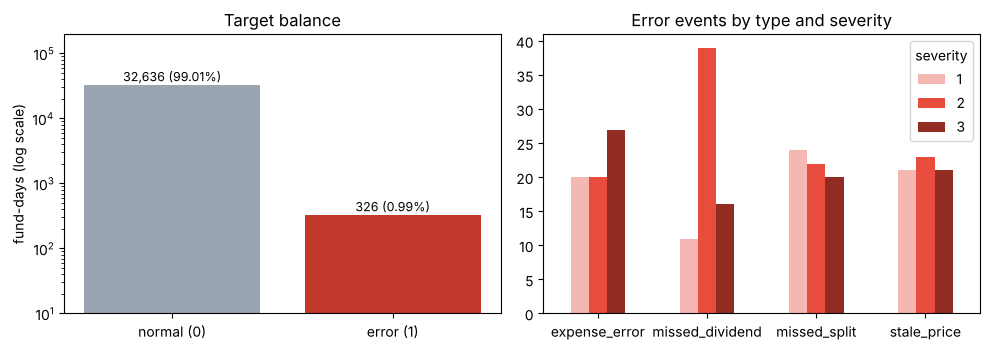

In [2]:
ev = d[y == 1].groupby("event_id").first()
print("Error events by type and severity:")
display(pd.crosstab(ev["atype"], ev["sev"], margins=True))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
vc = y.value_counts().sort_index()
ax[0].bar(["normal (0)", "error (1)"], vc.values, color=["#9aa5b1", "#c0392b"])
ax[0].set_yscale("log"); ax[0].set_ylabel("fund-days (log scale)"); ax[0].set_title("Target balance")
for i, v in enumerate(vc.values):
    ax[0].text(i, v * 1.15, f"{v:,} ({v / vc.sum():.2%})", ha="center", fontsize=9)
ax[0].set_ylim(10, vc.max() * 6)
pd.crosstab(ev["atype"], ev["sev"]).plot(kind="bar", ax=ax[1], rot=0, color=["#f5b7b1", "#e74c3c", "#922b21"])
ax[1].set_title("Error events by type and severity"); ax[1].set_xlabel(""); ax[1].legend(title="severity")
plt.tight_layout(); plt.savefig(Path("..") / "figures" / "target_distribution.png", dpi=130); plt.show()

## 2 | Baselines at a fixed 5% review budget
The analyst can review about 5% of fund-days inside the release window, so every method is compared at that budget. The primary metric is event recall: the share of injected error events with at least one flagged day.

In [3]:
rows = []
rows.append({"method": "Majority class (flag nothing)", "flag rate": 0.0, "event recall": 0.0})
for name, flag in [("50 bps rule, raw return", d["ret_obs"].abs() > nd.THRESH),
                   ("50 bps rule, benchmark-adjusted", d["adj_ret"].abs() > nd.THRESH)]:
    rows.append({"method": name, "flag rate": flag.mean(), "event recall": nd.event_recall(d, flag.values)})
cap = nd.review_top(d["adj_ret"].abs().values)
rows.append({"method": "Benchmark-adjusted move, top 5%", "flag rate": cap.mean(), "event recall": nd.event_recall(d, cap)})
display(pd.DataFrame(rows).round(3))

,method,flag rate,event recall
0,Majority class (flag nothing),0.000,0.000
1,"50 bps rule, raw return",0.459,0.481
2,"50 bps rule, benchmark-adjusted",0.138,0.557
3,"Benchmark-adjusted move, top 5%",0.050,0.322


## 3 | Current primary model under fund-level cross-validation
Logistic regression on the three Week 6 features, scaled inside a pipeline, evaluated on 5 folds x 5 repeats that hold out whole funds (stratified by asset class).

In [4]:
X, fund = d[nd.PRIMARY_FEATURES], d["ticker"]
res = []
for rep in range(5):
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=rep)
    for k, (tr, te) in enumerate(cv.split(X, d["asset_class"], groups=fund)):
        m = Pipeline([("scale", StandardScaler()),
                      ("lr", LogisticRegression(class_weight="balanced", max_iter=2000))]).fit(X.iloc[tr], y.iloc[tr])
        s = m.predict_proba(X.iloc[te])[:, 1]
        res.append({"recall": nd.event_recall(d.iloc[te], nd.review_top(s, seed=rep * 10 + k)),
                    "pr_auc": average_precision_score(y.iloc[te], s)})
res = pd.DataFrame(res)
print(f"Event recall at 5%: mean {res.recall.mean():.2f}, SD {res.recall.std():.2f}, "
      f"range {res.recall.min():.2f} to {res.recall.max():.2f} (25 folds)")
print(f"PR-AUC: mean {res.pr_auc.mean():.2f}, SD {res.pr_auc.std():.2f}")

Event recall at 5%: mean 0.67, SD 0.10, range 0.49 to 0.89 (25 folds)
PR-AUC: mean 0.37, SD 0.10


## 4 | Notes
- Accuracy is not used: flagging nothing is about 99% accurate and catches no errors.
- The weekly experiments in `src/experiments/` extend this notebook: estimate variability (Week 5), feature representation (Week 6), kNN and Naive Bayes (Week 7), trees and ensembles plus a leave-one-error-type-out test (Week 8).
- Results describe injected errors on public data. They are not evidence about real administrator error rates.